In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import datetime    
from sklearn.preprocessing import MinMaxScaler

loading my dataset and checking if its okay

In [2]:
df = pd.read_csv(filepath_or_buffer=r"D:\Code Practice\Simplilearn\02 IHFC AIML Applied Data Science with Python\Project 1\AAL_Sales_Analysis\data\AusApparalSales4thQrt2020.csv", parse_dates= ["Date"])
pd.set_option("display.max_columns", None)
df.head()

,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,8,20000
1,2020-10-01,Morning,WA,Men,8,20000
2,2020-10-01,Morning,WA,Women,4,10000
3,2020-10-01,Morning,WA,Seniors,15,37500
4,2020-10-01,Afternoon,WA,Kids,3,7500


# Task 1 

- checking for null values values in entire dataset.

In [3]:
df.isna().any()

Date     False
Time     False
State    False
Group    False
Unit     False
Sales    False
dtype: bool

In [4]:
df.notna().any()

Date     True
Time     True
State    True
Group    True
Unit     True
Sales    True
dtype: bool

- dropping duplicate values from the dataset.

In [5]:
df = df.drop_duplicates()

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    7560 non-null   datetime64[us]
 1   Time    7560 non-null   str           
 2   State   7560 non-null   str           
 3   Group   7560 non-null   str           
 4   Unit    7560 non-null   int64         
 5   Sales   7560 non-null   int64         
dtypes: datetime64[us](1), int64(2), str(3)
memory usage: 354.5 KB


- **filling null values** of **numerical columns** with the **mean of respective column**
- but `none of the columns` has `null values`

In [7]:
df.fillna(df.mean(numeric_only=True), inplace=True)

,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,8,20000
1,2020-10-01,Morning,WA,Men,8,20000
2,2020-10-01,Morning,WA,Women,4,10000
3,2020-10-01,Morning,WA,Seniors,15,37500
4,2020-10-01,Afternoon,WA,Kids,3,7500
...,...,...,...,...,...,...
7555,2020-12-30,Afternoon,TAS,Seniors,14,35000
7556,2020-12-30,Evening,TAS,Kids,15,37500
7557,2020-12-30,Evening,TAS,Men,15,37500
7558,2020-12-30,Evening,TAS,Women,11,27500


- **dropping null values** from `df`

In [8]:
df.dropna(inplace=True)

- `MinMaxScaler` - I'm using it for normalising the numerical columns like **sales** and **unit**

In [9]:
scaler = MinMaxScaler()

In [10]:
df_scale = df[["Date", "Time", "State", "Group"]].copy()
df_scale[["Unit", "Sales"]] = scaler.fit_transform(
    df[["Unit", "Sales"]]
)
df_scale.head()

,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,0.095238,0.095238
1,2020-10-01,Morning,WA,Men,0.095238,0.095238
2,2020-10-01,Morning,WA,Women,0.031746,0.031746
3,2020-10-01,Morning,WA,Seniors,0.206349,0.206349
4,2020-10-01,Afternoon,WA,Kids,0.015873,0.015873


In [11]:
df_unit_and_sales = df.groupby(by="Date").agg({'Unit':'sum','Sales':'sum'})
df_unit_and_sales.head()

,Unit,Sales
Date,,
2020-10-01,1488,3720000
2020-10-02,1486,3715000
2020-10-03,1556,3890000
2020-10-04,1488,3720000
2020-10-05,1545,3862500


# Task 2

- creating 3 different dataframes of 3 different months `october`, `november`, `december`

In [12]:
df_oct = df[df["Date"].dt.month == 10].copy()
df_nov = df[df["Date"].dt.month == 11].copy()
df_dec = df[df["Date"].dt.month == 12].copy()

In [13]:
df_oct.head()

,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,8,20000
1,2020-10-01,Morning,WA,Men,8,20000
2,2020-10-01,Morning,WA,Women,4,10000
3,2020-10-01,Morning,WA,Seniors,15,37500
4,2020-10-01,Afternoon,WA,Kids,3,7500


In [14]:
df_nov.head()

,Date,Time,State,Group,Unit,Sales
2520,2020-11-01,Morning,WA,Kids,4,10000
2521,2020-11-01,Morning,WA,Men,6,15000
2522,2020-11-01,Morning,WA,Women,4,10000
2523,2020-11-01,Morning,WA,Seniors,7,17500
2524,2020-11-01,Afternoon,WA,Kids,8,20000


In [15]:
df_dec.head()

,Date,Time,State,Group,Unit,Sales
5040,2020-12-01,Morning,WA,Kids,9,22500
5041,2020-12-01,Morning,WA,Men,11,27500
5042,2020-12-01,Morning,WA,Women,15,37500
5043,2020-12-01,Morning,WA,Seniors,13,32500
5044,2020-12-01,Afternoon,WA,Kids,13,32500


- getting information of descriptive statistics of 3 different dataframes of 3 different months

In [16]:
df_oct.describe()

,Date,Unit,Sales
count,2520,2520.000000,2520.000000
mean,2020-10-15 12:00:00,18.141270,45353.174603
min,2020-10-01 00:00:00,3.000000,7500.000000
25%,2020-10-08 00:00:00,9.000000,22500.000000
50%,2020-10-15 12:00:00,14.000000,35000.000000
75%,2020-10-23 00:00:00,27.000000,67500.000000
max,2020-10-30 00:00:00,50.000000,125000.000000
std,NaN,11.944521,29861.302213


In [17]:
df_nov.describe()

,Date,Unit,Sales
count,2520,2520.000000,2520.000000
mean,2020-11-15 12:00:00,14.394048,35985.119048
min,2020-11-01 00:00:00,2.000000,5000.000000
25%,2020-11-08 00:00:00,6.000000,15000.000000
50%,2020-11-15 12:00:00,10.000000,25000.000000
75%,2020-11-23 00:00:00,22.000000,55000.000000
max,2020-11-30 00:00:00,45.000000,112500.000000
std,NaN,10.946470,27366.175823


In [18]:
df_dec.describe()

,Date,Unit,Sales
count,2520,2520.000000,2520.000000
mean,2020-12-15 12:00:00,21.480952,53702.380952
min,2020-12-01 00:00:00,5.000000,12500.000000
25%,2020-12-08 00:00:00,10.000000,25000.000000
50%,2020-12-15 12:00:00,15.000000,37500.000000
75%,2020-12-23 00:00:00,31.000000,77500.000000
max,2020-12-30 00:00:00,65.000000,162500.000000
std,NaN,14.554181,36385.451298


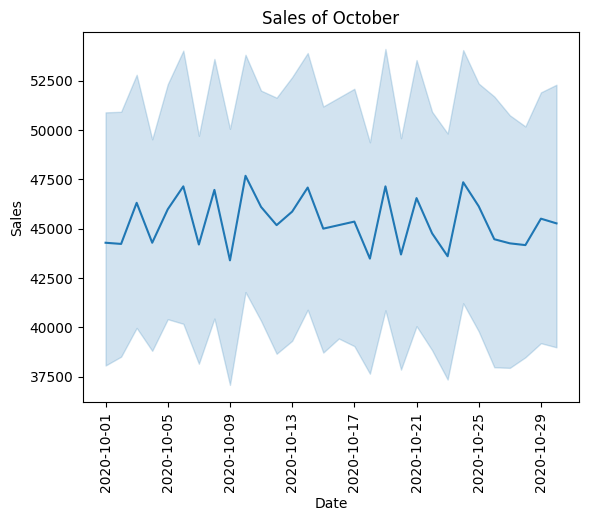

In [19]:
sns.lineplot(data= df_oct, x= "Date", y= "Sales")
plt.title("Sales of October")
plt.xticks(rotation=90)
plt.show()

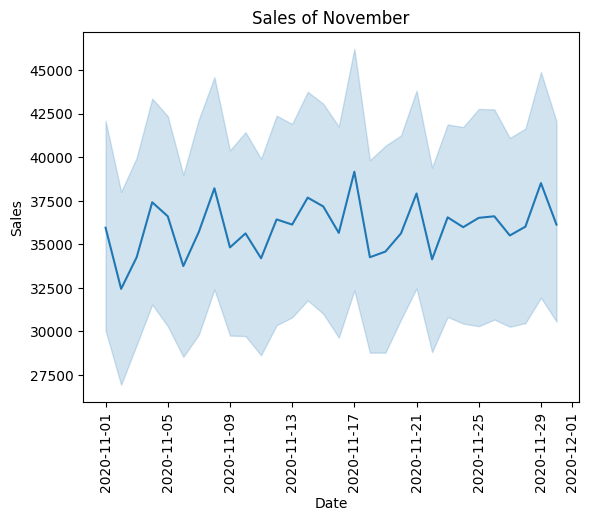

In [20]:
sns.lineplot(data= df_nov, x= "Date", y="Sales")
plt.title("Sales of November")
plt.xticks(rotation=90)
plt.show()

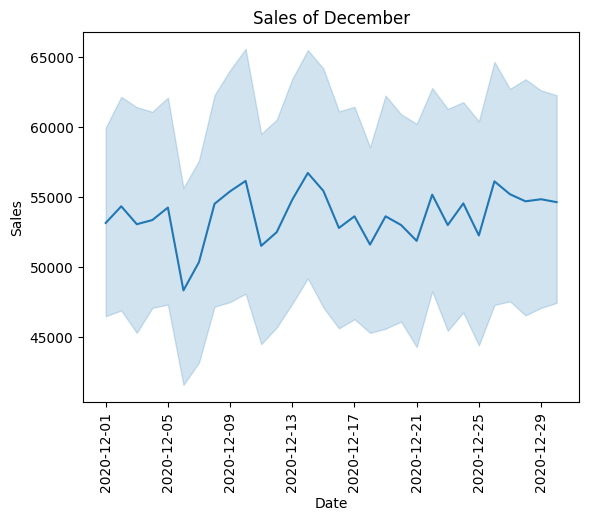

In [21]:
sns.lineplot(data= df_dec, x= "Date", y="Sales")
plt.title("Sales of December")
plt.xticks(rotation=90)
plt.show()

- comparing between units and sales of different months

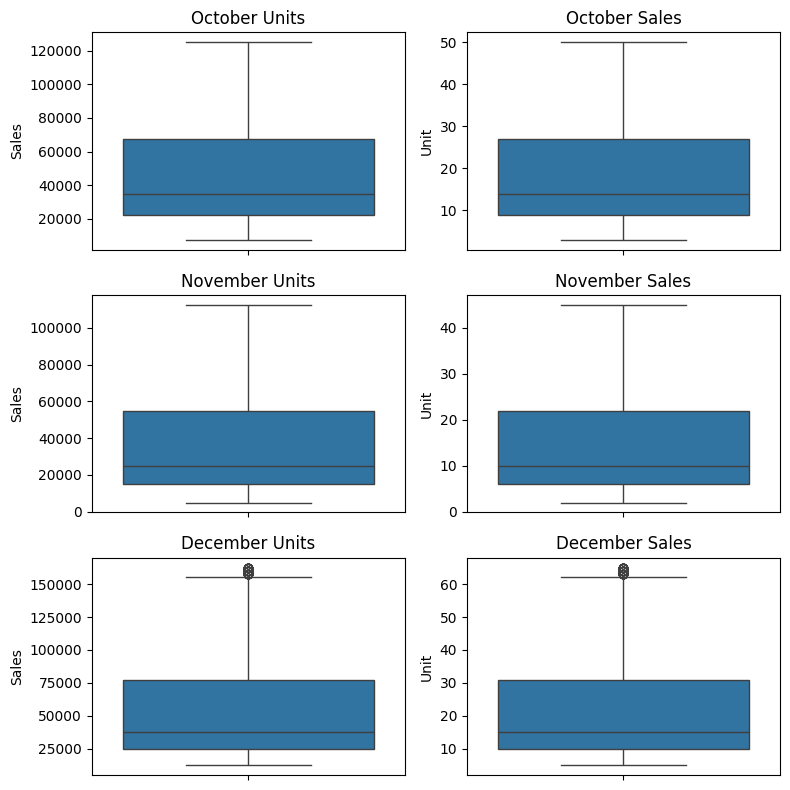

In [22]:
fig, ax = plt.subplots(3, 2, figsize=(8, 8))
ax = ax.flatten()

sns.boxplot(data=df_oct, y="Unit", ax=ax[1])
ax[0].set_title("October Units")

sns.boxplot(data=df_oct, y="Sales", ax=ax[0])
ax[1].set_title("October Sales")

sns.boxplot(data=df_nov, y="Unit", ax=ax[3])
ax[2].set_title("November Units")

sns.boxplot(data=df_nov, y="Sales", ax=ax[2])
ax[3].set_title("November Sales")

sns.boxplot(data=df_dec, y="Unit", ax=ax[5])
ax[4].set_title("December Units")

sns.boxplot(data=df_dec, y="Sales", ax=ax[4])
ax[5].set_title("December Sales")


plt.tight_layout()
plt.show()

comparing between total sales of different months

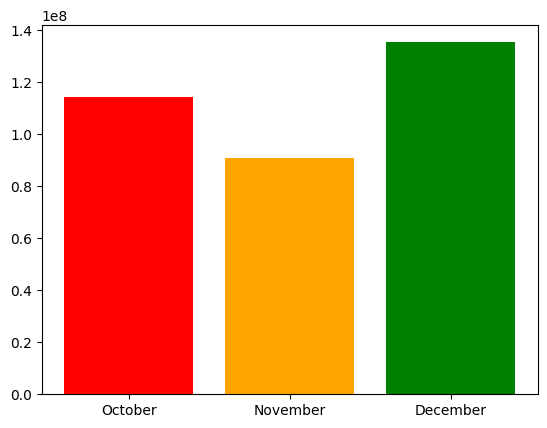

In [23]:
plt.bar(['October', 'November', "December"], [df_oct["Sales"].sum(), df_nov["Sales"].sum(), df_dec["Sales"].sum()], color=['red', 'orange', 'green'])
plt.show()

comparing monthly sales all together

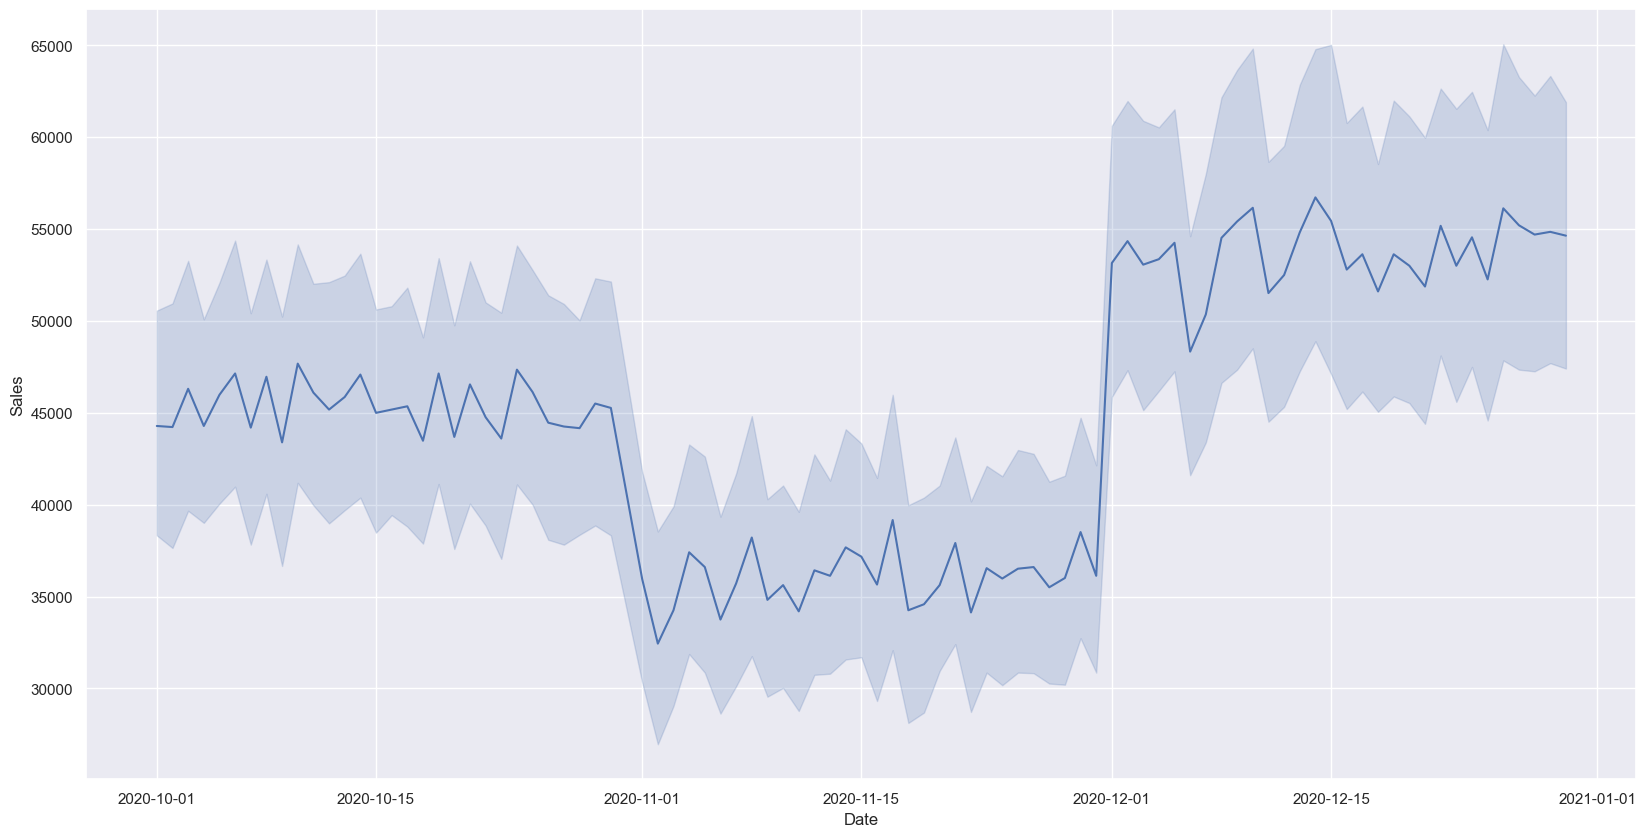

In [24]:
sns.set(rc={'figure.figsize':(20,10)})
sns.lineplot(x = 'Date', y = 'Sales', data = df)
plt.show()

- looking for maximum sales among the group

In [25]:
print("The Group where sales is maximum is - ",end=' ')
df[["Group"]].iloc[df["Sales"].idxmax()]

The Group where sales is maximum is -  

Group     Seniors
Name: 5423, dtype: str

# Task 3

- State-wise sales analysis for different demographic groups

In [26]:
df.groupby(["State", "Group"])[["Sales"]].sum()

Sales
State Group            
NSW   Kids     18587500
      Men      19022500
      Seniors  18187500
      Women    19172500
NT    Kids      5700000
      Men       5762500
      Seniors   5465000
      Women     5652500
QLD   Kids      8510000
      Men       8392500
      Seniors   8190000
      Women     8325000
SA    Kids     14515000
      Men      14655000
      Seniors  14717500
      Women    14970000
TAS   Kids      5775000
      Men       5757500
      Seniors   5650000
      Women     5577500
VIC   Kids     26360000
      Men      26407500
      Seniors  26315000
      Women    26482500
WA    Kids      5625000
      Men       5752500
      Seniors   5512500
      Women     5262500

- groupwise sales analysis of accross varies states

In [27]:
pd.pivot_table(df, values="Sales", index=["State"], columns=["Group"], aggfunc=np.sum, fill_value=0).reset_index()

Group,State,Kids,Men,Seniors,Women
0,NSW,18587500,19022500,18187500,19172500
1,NT,5700000,5762500,5465000,5652500
2,QLD,8510000,8392500,8190000,8325000
3,SA,14515000,14655000,14717500,14970000
4,TAS,5775000,5757500,5650000,5577500
5,VIC,26360000,26407500,26315000,26482500
6,WA,5625000,5752500,5512500,5262500


In [28]:
group_pivot = pd.pivot_table(df[['Group','Sales','Unit']], index='Group', aggfunc=['sum', 'mean'])
group_pivot

sum                 mean           
            Sales   Unit         Sales       Unit
Group                                            
Kids     85072500  34029  45011.904762  18.004762
Men      85750000  34300  45370.370370  18.148148
Seniors  84037500  33615  44464.285714  17.785714
Women    85442500  34177  45207.671958  18.083069

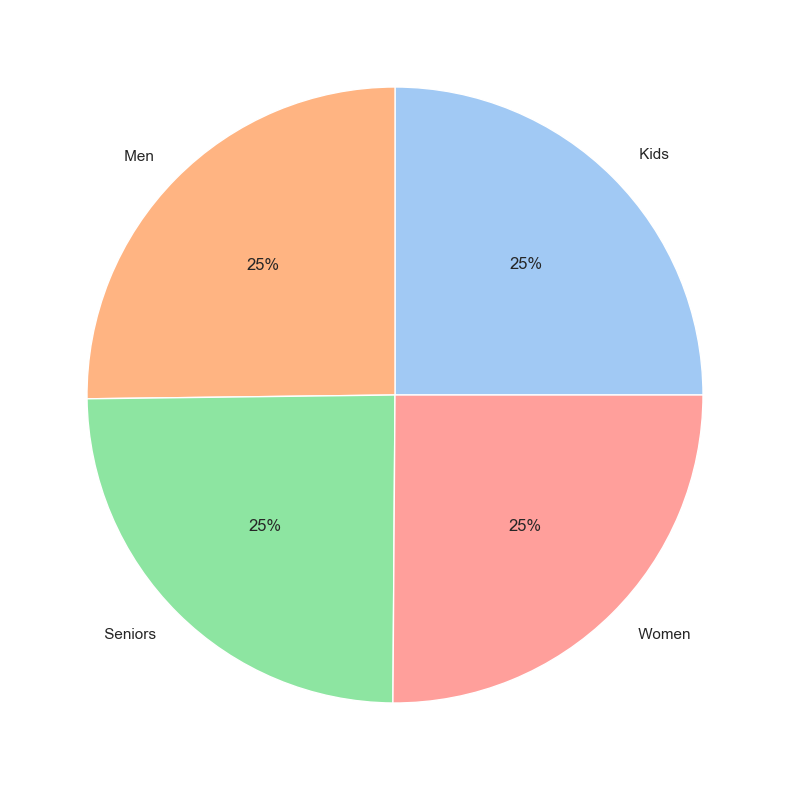

In [29]:
labels = group_pivot['mean']['Sales'].index.to_list()
# print(labels)
colors = sns.color_palette('pastel')[0:5]
plt.pie(group_pivot['mean']['Sales'], labels=labels, colors=colors, autopct='%.0f%%')
plt.show()

- time wise sales analysis

In [30]:
time_pivot = pd.pivot_table(df[['Time','Sales','Unit']], index='Time', aggfunc=['sum', 'mean' ])
time_pivot

sum                 mean           
               Sales   Unit         Sales       Unit
Time                                                
Afternoon  114007500  45603  45241.071429  18.096429
Evening    112087500  44835  44479.166667  17.791667
Morning    114207500  45683  45320.436508  18.128175

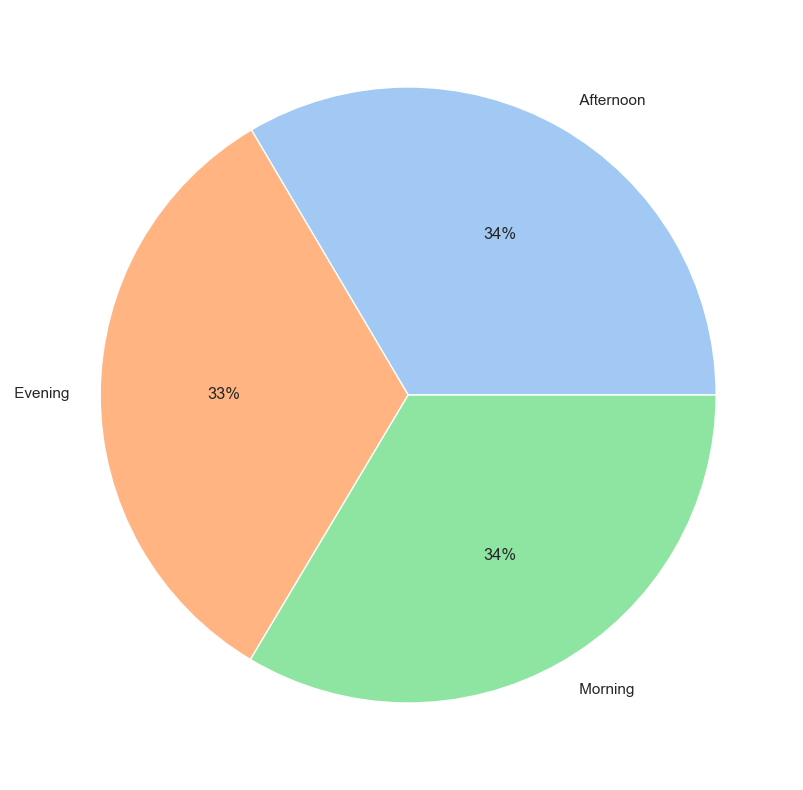

In [31]:
labels = time_pivot['mean']['Sales'].index.to_list()
# print(labels)
colors = sns.color_palette('pastel')[0:5]
plt.pie(time_pivot['mean']['Sales'], labels=labels, colors=colors, autopct='%.0f%%')
plt.show()